<a href="https://colab.research.google.com/github/mldyharinn/Visi-Komputer/blob/main/JS05_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch

print("Versi PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
else:
    print("Saat ini menggunakan CPU")


Versi PyTorch: 2.11.0+cu130
GPU tersedia: True
Nama GPU: Tesla T4


In [2]:
%pip install -q transformers

In [3]:
import os
import time
import random
import json

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Perangkat:", DEVICE)

if DEVICE == "cuda":
    print("Nama GPU:", torch.cuda.get_device_name(0))
else:
    print("Mode CPU aktif: konfigurasi lebih ringan")

CFG = {
    "IMG": 128 if CEPAT else 256,
    "N_TRAIN": 320 if CEPAT else 2000,
    "N_TEST": 100 if CEPAT else 500,
    "BATCH": 16,
    "EP_UNET": 6 if CEPAT else 15,
    "EP_DLV3": 2 if CEPAT else 6,
    "EP_SEGF": 3 if CEPAT else 6,
    "BASE_CH": 16 if CEPAT else 32,
}

print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)")
print("Konfigurasi:", CFG)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

WAKTU = {}

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Perangkat: cuda
Nama GPU: Tesla T4
Mode: PENUH (GPU)
Konfigurasi: {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}


In [4]:
# === D1.1: Unduh subset Oxford-IIIT Pet ===
import tarfile
import urllib.request
import os
import time

URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)

    ann = f"{root}/annotations.tar.gz"

    if not os.path.exists(ann):
        print("Mengunduh anotasi dataset...")
        urllib.request.urlretrieve(URL_ANN, ann)

    split = {}
    trimaps = {}

    print("Membaca daftar data dan masker...")

    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if (
                m.name.endswith("annotations/trainval.txt")
                or m.name.endswith("annotations/test.txt")
            ):
                bagian = "train" if "trainval" in m.name else "test"
                file_obj = t.extractfile(m)

                if file_obj is not None:
                    for line in file_obj.read().decode().splitlines():
                        if line.strip():
                            split[line.split()[0]] = bagian

            elif (
                "/trimaps/" in m.name
                and m.name.endswith(".png")
                and "._" not in m.name
            ):
                file_obj = t.extractfile(m)

                if file_obj is not None:
                    nama_id = os.path.basename(m.name)[:-4]
                    trimaps[nama_id] = file_obj.read()

    def hitung():
        gambar_ada = [
            f[:-4]
            for f in os.listdir(f"{root}/images")
            if f.endswith(".jpg")
        ]

        latih = sorted(
            i for i in gambar_ada if split.get(i) == "train"
        )
        uji = sorted(
            i for i in gambar_ada if split.get(i) == "test"
        )

        return latih, uji

    tr, te = hitung()

    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia.")
        return tr[:n_train], te[:n_test]

    print("Mengunduh gambar yang dibutuhkan...")
    print("Proses ini bisa memerlukan beberapa menit.")

    with urllib.request.urlopen(URL_IMG) as resp:
        with tarfile.open(fileobj=resp, mode="r|gz") as t:
            for m in t:
                nama = os.path.basename(m.name)

                if not nama.endswith(".jpg"):
                    continue

                iid = nama[:-4]
                bagian = split.get(iid)

                if iid not in trimaps or bagian is None:
                    continue

                if bagian == "train" and len(tr) >= n_train:
                    continue

                if bagian == "test" and len(te) >= n_test:
                    continue

                if bagian == "train":
                    tujuan = f"{root}/images/{nama}"
                else:
                    tujuan = f"{root}/images/{nama}"

                file_obj = t.extractfile(m)

                if file_obj is None:
                    continue

                with open(tujuan, "wb") as f:
                    f.write(file_obj.read())

                with open(f"{root}/trimaps/{iid}.png", "wb") as f:
                    f.write(trimaps[iid])

                if bagian == "train":
                    tr.append(iid)
                else:
                    te.append(iid)

                if len(tr) >= n_train and len(te) >= n_test:
                    break

    tr, te = hitung()

    print("Selesai mengunduh subset.")
    return tr[:n_train], te[:n_test]


t0 = time.time()

ROOT = "data/pet_subset"

ID_TRAIN, ID_TEST = ambil_subset_pet(
    ROOT,
    CFG["N_TRAIN"],
    CFG["N_TEST"]
)

print("Jumlah citra latih:", len(ID_TRAIN))
print("Jumlah citra uji:", len(ID_TEST))
print("Waktu:", round(time.time() - t0, 1), "detik")
print(
    "Jumlah ras pada data latih:",
    len({i.rsplit("_", 1)[0] for i in ID_TRAIN})
)

Mengunduh anotasi dataset...
Membaca daftar data dan masker...
Mengunduh gambar yang dibutuhkan...
Proses ini bisa memerlukan beberapa menit.
Selesai mengunduh subset.
Jumlah citra latih: 2000
Jumlah citra uji: 500
Waktu: 4.8 detik
Jumlah ras pada data latih: 37


In [5]:
# === D1.2: Membuat Dataset PyTorch ===

MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


def muat_pasangan(iid, size):
    img = (
        Image.open(f"{ROOT}/images/{iid}.jpg")
        .convert("RGB")
        .resize((size, size), Image.BILINEAR)
    )

    tri = (
        Image.open(f"{ROOT}/trimaps/{iid}.png")
        .resize((size, size), Image.NEAREST)
    )

    return np.array(img), np.array(tri)


class PetSegDataset(torch.utils.data.Dataset):

    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]

        self.img = torch.from_numpy(
            np.stack([p[0] for p in pairs])
        ).permute(0, 3, 1, 2)

        self.tri = torch.from_numpy(
            np.stack([p[1] for p in pairs])
        )

        self.augment = augment

    def __len__(self):
        return len(self.img)

    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]

        # Nilai 1 = hewan, 0 = latar belakang
        y = (tri == 1).float().unsqueeze(0)

        # Piksel batas bernilai 0 karena diabaikan
        valid = (tri != 3).float().unsqueeze(0)

        # Augmentasi: membalik gambar secara horizontal
        if self.augment and random.random() < 0.5:
            x = x.flip(-1)
            y = y.flip(-1)
            valid = valid.flip(-1)

        x = (x - MEAN) / STD

        return x, y, valid


t0 = time.time()

ds_train = PetSegDataset(
    ID_TRAIN,
    CFG["IMG"],
    augment=True
)

ds_test = PetSegDataset(
    ID_TEST,
    CFG["IMG"],
    augment=False
)

dl_train = torch.utils.data.DataLoader(
    ds_train,
    batch_size=CFG["BATCH"],
    shuffle=True
)

dl_test = torch.utils.data.DataLoader(
    ds_test,
    batch_size=CFG["BATCH"],
    shuffle=False
)

x, y, v = ds_train[0]

print("Bentuk gambar:", tuple(x.shape))
print("Bentuk masker:", tuple(y.shape))
print("Bentuk masker valid:", tuple(v.shape))

tri_all = ds_train.tri

print(
    "Proporsi piksel hewan: %.3f | latar: %.3f | batas: %.3f"
    % tuple(
        ((tri_all == k).float().mean().item())
        for k in (1, 2, 3)
    )
)

WAKTU["D1 data"] = time.time() - t0
print("Waktu persiapan data:", round(WAKTU["D1 data"], 1), "detik")

Bentuk gambar: (3, 256, 256)
Bentuk masker: (1, 256, 256)
Bentuk masker valid: (1, 256, 256)
Proporsi piksel hewan: 0.301 | latar: 0.584 | batas: 0.114
Waktu persiapan data: 14.5 detik


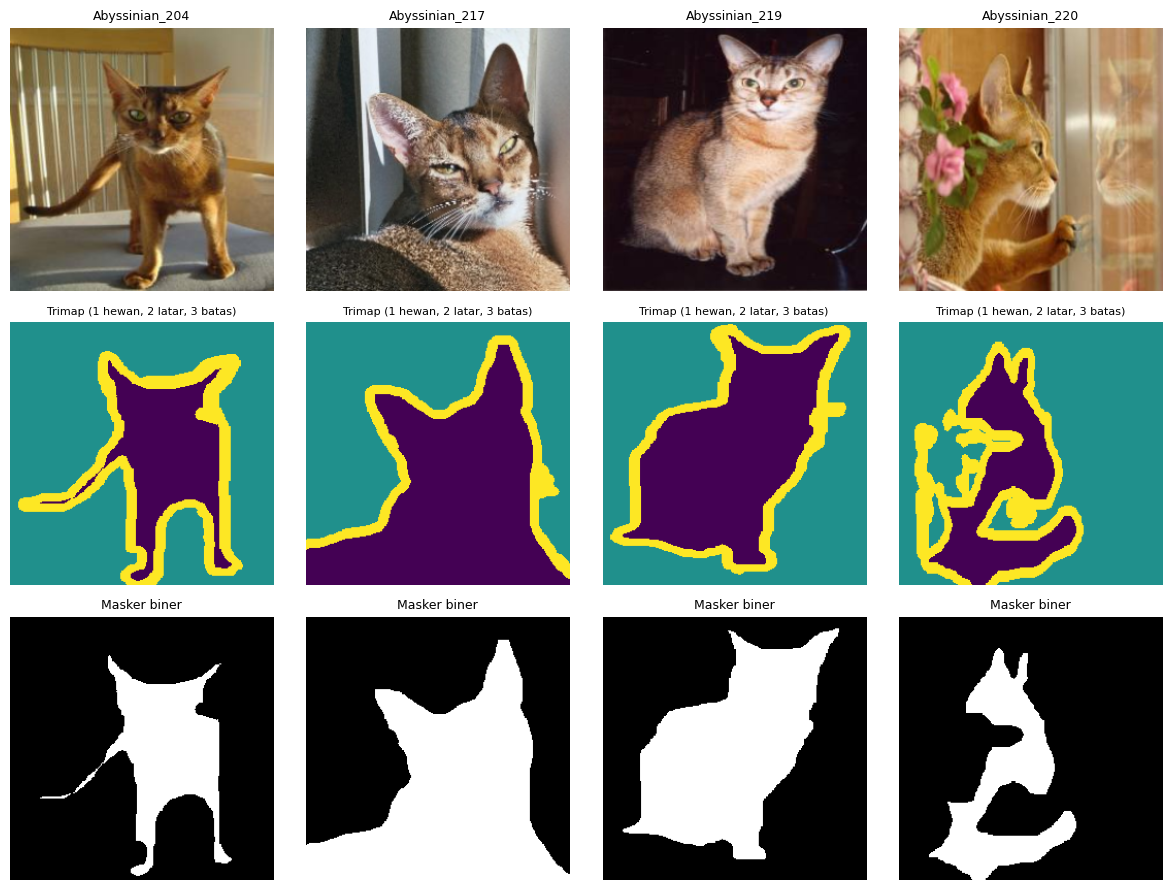

In [6]:
# === D1.3: Visualisasi citra, trimap, dan masker biner ===

def denorm(x):
    return (
        (x * STD + MEAN)
        .clamp(0, 1)
        .permute(1, 2, 0)
        .numpy()
    )


fig, ax = plt.subplots(3, 4, figsize=(12, 9))

for k in range(4):
    x, y, v = ds_test[k]

    ax[0, k].imshow(denorm(x))
    ax[0, k].set_title(ID_TEST[k], fontsize=9)

    ax[1, k].imshow(
        ds_test.tri[k],
        cmap="viridis",
        vmin=1,
        vmax=3
    )
    ax[1, k].set_title(
        "Trimap (1 hewan, 2 latar, 3 batas)",
        fontsize=8
    )

    ax[2, k].imshow(y[0], cmap="gray")
    ax[2, k].set_title("Masker biner", fontsize=9)

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/js05_d1_contoh_data.png",
    dpi=120
)
plt.show()

In [7]:
tri_test = ds_test.tri

for nilai, nama in [
    (1, "Hewan"),
    (2, "Latar"),
    (3, "Batas")
]:
    proporsi = (tri_test == nilai).float().mean().item()
    print(f"{nama}: {proporsi:.4f} ({proporsi * 100:.2f}%)")

Hewan: 0.3013 (30.13%)
Latar: 0.5748 (57.48%)
Batas: 0.1239 (12.39%)


In [8]:

# === D2.1 Arsitektur U-Net kecil ===

class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),

            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True)
        )


class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()

        c = [base, base*2, base*4, base*8, base*16]

        # Encoder: mengambil fitur gambar
        self.enc = nn.ModuleList(
            [DoubleConv(in_ch, c[0])] +
            [DoubleConv(c[i], c[i+1]) for i in range(4)]
        )

        # Decoder: memperbesar kembali ukuran fitur
        self.up = nn.ModuleList([
            nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2)
            for i in reversed(range(4))
        ])

        # Menggabungkan fitur encoder dan decoder
        self.dec = nn.ModuleList([
            DoubleConv(c[i]*2, c[i])
            for i in reversed(range(4))
        ])

        # Menghasilkan prediksi masker
        self.head = nn.Conv2d(c[0], out_ch, 1)

    def forward(self, x):
        skips = []

        # Encoder
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)

        # Bottleneck
        x = skips.pop()

        # Decoder + skip connection
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))

        return self.head(x)


# Membuat model dan memindahkannya ke GPU atau CPU
unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)

print(
    "Jumlah parameter U-Net: %.2f juta"
    % (sum(p.numel() for p in unet.parameters()) / 1e6)
)

# Memeriksa ukuran hasil prediksi
print(
    "Uji bentuk keluaran:",
    tuple(
        unet(
            torch.zeros(
                2, 3, CFG["IMG"], CFG["IMG"],
                device=DEVICE
            )
        ).shape
    )
)


Jumlah parameter U-Net: 7.76 juta
Uji bentuk keluaran: (2, 1, 256, 256)


In [9]:

# === D2.2 Loss BCE + Dice dan fungsi pelatihan ===

def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    # BCE: mengukur kesalahan prediksi setiap piksel
    bce = F.binary_cross_entropy_with_logits(
        logit, y, reduction="none"
    )

    # Hanya menghitung piksel yang valid
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)

    # Dice: mengukur kesesuaian bentuk masker
    p = torch.sigmoid(logit) * valid

    inter = (p * y * valid).sum(dim=(1, 2, 3))

    dice = 1 - (
        (2 * inter + eps) /
        (
            p.sum(dim=(1, 2, 3))
            + (y * valid).sum(dim=(1, 2, 3))
            + eps
        )
    )

    return bce + w_dice * dice.mean()


def latih(model, forward, epochs, lr, nama, param_groups=None):
    opt = torch.optim.AdamW(
        param_groups or model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    riwayat = {"train": [], "test": []}
    t0 = time.time()

    for ep in range(epochs):
        model.train()
        tot = 0

        # Pelatihan menggunakan data latih
        for x, y, v in dl_train:
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            v = v.to(DEVICE)

            loss = bce_dice_loss(forward(model, x), y, v)

            opt.zero_grad()
            loss.backward()
            opt.step()

            tot += loss.item() * len(x)

        # Mengukur loss pada data uji
        model.eval()
        tot_te = 0

        with torch.no_grad():
            for x, y, v in dl_test:
                x = x.to(DEVICE)
                y = y.to(DEVICE)
                v = v.to(DEVICE)

                loss_te = bce_dice_loss(
                    forward(model, x), y, v
                )
                tot_te += loss_te.item() * len(x)

        riwayat["train"].append(tot / len(ds_train))
        riwayat["test"].append(tot_te / len(ds_test))

        print(
            f"[{nama}] epoch {ep+1}/{epochs} "
            f"loss latih {riwayat['train'][-1]:.4f} "
            f"loss uji {riwayat['test'][-1]:.4f} "
            f"({time.time()-t0:.0f} s)"
        )

    WAKTU[nama] = time.time() - t0
    return riwayat


# Menjalankan pelatihan U-Net
fwd_unet = lambda m, x: m(x)

set_seed(42)

hist_unet = latih(
    unet,
    fwd_unet,
    CFG["EP_UNET"],
    1e-3,
    "U-Net (dari nol)"
)


[U-Net (dari nol)] epoch 1/15 loss latih 0.8975 loss uji 0.8614 (50 s)
[U-Net (dari nol)] epoch 2/15 loss latih 0.7442 loss uji 0.9671 (104 s)
[U-Net (dari nol)] epoch 3/15 loss latih 0.6490 loss uji 0.6136 (163 s)
[U-Net (dari nol)] epoch 4/15 loss latih 0.5804 loss uji 0.5644 (222 s)
[U-Net (dari nol)] epoch 5/15 loss latih 0.5286 loss uji 0.4939 (281 s)
[U-Net (dari nol)] epoch 6/15 loss latih 0.4687 loss uji 0.4822 (341 s)
[U-Net (dari nol)] epoch 7/15 loss latih 0.4395 loss uji 0.4636 (400 s)
[U-Net (dari nol)] epoch 8/15 loss latih 0.4035 loss uji 0.3701 (460 s)
[U-Net (dari nol)] epoch 9/15 loss latih 0.3844 loss uji 0.3789 (520 s)
[U-Net (dari nol)] epoch 10/15 loss latih 0.3623 loss uji 0.3393 (580 s)
[U-Net (dari nol)] epoch 11/15 loss latih 0.3398 loss uji 0.3364 (639 s)
[U-Net (dari nol)] epoch 12/15 loss latih 0.3219 loss uji 0.3367 (699 s)
[U-Net (dari nol)] epoch 13/15 loss latih 0.3144 loss uji 0.3531 (758 s)
[U-Net (dari nol)] epoch 14/15 loss latih 0.3011 loss uji 0.3

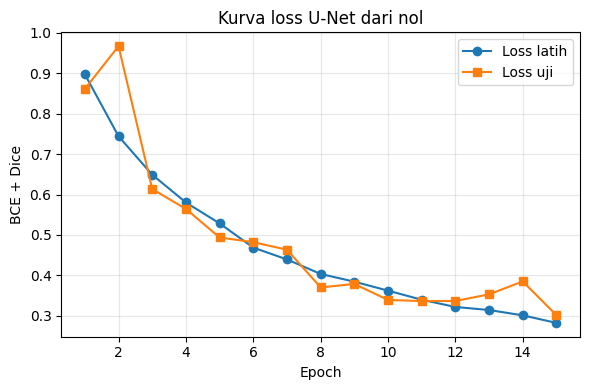

In [10]:

# === D2.3 Kurva loss U-Net ===

plt.figure(figsize=(6, 4))

ep = range(1, len(hist_unet["train"]) + 1)

plt.plot(
    ep, hist_unet["train"],
    "o-", label="Loss latih"
)

plt.plot(
    ep, hist_unet["test"],
    "s-", label="Loss uji"
)

plt.xlabel("Epoch")
plt.ylabel("BCE + Dice")
plt.title("Kurva loss U-Net dari nol")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/js05_d2_kurva_unet.png",
    dpi=120
)

plt.show()


In [16]:

# Simpan hasil awal sebelum eksperimen
hasil_awal_d2 = HASIL["U-Net (dari nol)"].copy()

print("Hasil awal (BCE + Dice):")
print(ringkas(hasil_awal_d2))


Hasil awal (BCE + Dice):
{'IoU_hewan': 0.8268, 'IoU_latar': 0.9057, 'mIoU': 0.8662, 'Dice': 0.9052, 'PixelAcc': 0.935}


In [17]:

# === D2.1 Arsitektur U-Net kecil ===

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import random
import pandas as pd

# Pastikan konfigurasi dan DataLoader D1 sudah tersedia
os.makedirs("figures", exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True)
        )


class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()

        c = [base, base*2, base*4, base*8, base*16]

        self.enc = nn.ModuleList(
            [DoubleConv(in_ch, c[0])] +
            [DoubleConv(c[i], c[i+1]) for i in range(4)]
        )

        self.up = nn.ModuleList([
            nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2)
            for i in reversed(range(4))
        ])

        self.dec = nn.ModuleList([
            DoubleConv(c[i]*2, c[i])
            for i in reversed(range(4))
        ])

        self.head = nn.Conv2d(c[0], out_ch, 1)

    def forward(self, x):
        skips = []

        for i, blk in enumerate(self.enc):
            if i == 0:
                x = blk(x)
            else:
                x = blk(F.max_pool2d(x, 2))
            skips.append(x)

        x = skips.pop()

        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))

        return self.head(x)


# Membuat model U-Net
unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)

jumlah_parameter = sum(
    p.numel() for p in unet.parameters()
)

print("Device:", DEVICE)
print("Jumlah parameter U-Net:",
      round(jumlah_parameter / 1e6, 2), "juta")

# Memeriksa bentuk keluaran model
with torch.no_grad():
    contoh = torch.zeros(
        2, 3, CFG["IMG"], CFG["IMG"], device=DEVICE
    )
    keluaran = unet(contoh)

print("Bentuk input :", tuple(contoh.shape))
print("Bentuk output:", tuple(keluaran.shape))


Device: cuda
Jumlah parameter U-Net: 7.76 juta
Bentuk input : (2, 3, 256, 256)
Bentuk output: (2, 1, 256, 256)


HASIL U-NET AWAL (BCE + DICE)
{'IoU_hewan': 0.3439, 'IoU_latar': 0.0, 'mIoU': 0.172, 'Dice': 0.5118, 'PixelAcc': 0.3439}
Epoch 1/15 | Loss latih: 0.4552 | Loss uji: 0.3725
Epoch 2/15 | Loss latih: 0.3493 | Loss uji: 0.3495
Epoch 3/15 | Loss latih: 0.3097 | Loss uji: 0.3001
Epoch 4/15 | Loss latih: 0.2766 | Loss uji: 0.3144
Epoch 5/15 | Loss latih: 0.2555 | Loss uji: 0.2400
Epoch 6/15 | Loss latih: 0.2379 | Loss uji: 0.2425
Epoch 7/15 | Loss latih: 0.2235 | Loss uji: 0.2415
Epoch 8/15 | Loss latih: 0.2129 | Loss uji: 0.2277
Epoch 9/15 | Loss latih: 0.1999 | Loss uji: 0.2140
Epoch 10/15 | Loss latih: 0.1978 | Loss uji: 0.2166
Epoch 11/15 | Loss latih: 0.1784 | Loss uji: 0.2476
Epoch 12/15 | Loss latih: 0.1741 | Loss uji: 0.1844
Epoch 13/15 | Loss latih: 0.1592 | Loss uji: 0.1865
Epoch 14/15 | Loss latih: 0.1604 | Loss uji: 0.2207
Epoch 15/15 | Loss latih: 0.1605 | Loss uji: 0.1817

Waktu training BCE saja: 888.67 detik

HASIL U-NET BCE SAJA
{'IoU_hewan': 0.8116, 'IoU_latar': 0.9021, 'mIo

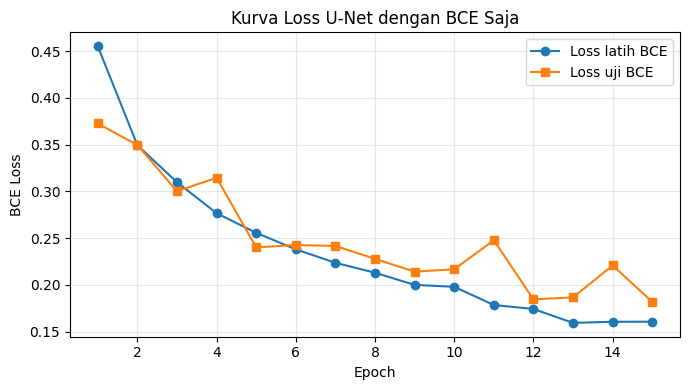


KESIMPULAN EKSPERIMEN
BCE saja memiliki mIoU lebih tinggi sebesar 0.6849 dibandingkan BCE + Dice.

Dice Loss membantu dengan mempertimbangkan tumpang tindih area prediksi dan masker target. Manfaatnya perlu dinilai berdasarkan hasil IoU dan Dice dari eksperimen.


In [18]:

# ============================================================
# TUGAS KECIL D2: PERBANDINGAN BCE + DICE DENGAN BCE SAJA
# ============================================================

import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
import time

# ------------------------------------------------------------
# 1. Simpan hasil model awal (BCE + Dice)
# ------------------------------------------------------------

hasil_awal = evaluasi(unet, fwd_unet)

print("HASIL U-NET AWAL (BCE + DICE)")
print(ringkas(hasil_awal))


# ------------------------------------------------------------
# 2. Buat model U-Net baru untuk eksperimen BCE saja
# ------------------------------------------------------------

set_seed(42)

unet_bce = UNet(base=CFG["BASE_CH"]).to(DEVICE)

optimizer = torch.optim.AdamW(
    unet_bce.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

epochs = CFG["EP_UNET"]
loss_train_bce = []
loss_test_bce = []

waktu_mulai = time.time()

# ------------------------------------------------------------
# 3. Latih ulang model dengan BCE saja (w_dice=0)
# ------------------------------------------------------------

for epoch in range(epochs):

    unet_bce.train()
    total_loss = 0.0

    for x, y, valid in dl_train:
        x = x.to(DEVICE)
        y = y.to(DEVICE)
        valid = valid.to(DEVICE)

        # Forward propagation
        logit = unet_bce(x)

        # w_dice=0 berarti hanya menggunakan BCE Loss
        loss = bce_dice_loss(
            logit,
            y,
            valid,
            w_dice=0
        )

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

    rata_train = total_loss / len(dl_train.dataset)
    loss_train_bce.append(rata_train)

    # Evaluasi loss pada data uji
    unet_bce.eval()
    total_test = 0.0

    with torch.no_grad():
        for x, y, valid in dl_test:
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            valid = valid.to(DEVICE)

            logit = unet_bce(x)

            loss = bce_dice_loss(
                logit,
                y,
                valid,
                w_dice=0
            )

            total_test += loss.item() * x.size(0)

    rata_test = total_test / len(dl_test.dataset)
    loss_test_bce.append(rata_test)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss latih: {rata_train:.4f} | "
        f"Loss uji: {rata_test:.4f}"
    )

waktu_bce = time.time() - waktu_mulai

print(f"\nWaktu training BCE saja: {waktu_bce:.2f} detik")


# ------------------------------------------------------------
# 4. Evaluasi IoU dan Dice
# ------------------------------------------------------------

hasil_bce = evaluasi(unet_bce, fwd_unet)

print("\nHASIL U-NET BCE SAJA")
print(ringkas(hasil_bce))


# ------------------------------------------------------------
# 5. Bandingkan metrik kedua model
# ------------------------------------------------------------

tabel = pd.DataFrame([
    {
        "Metode": "BCE + Dice",
        "IoU hewan": hasil_awal["IoU_hewan"],
        "IoU latar": hasil_awal["IoU_latar"],
        "mIoU": hasil_awal["mIoU"],
        "Dice": hasil_awal["Dice"]
    },
    {
        "Metode": "BCE saja",
        "IoU hewan": hasil_bce["IoU_hewan"],
        "IoU latar": hasil_bce["IoU_latar"],
        "mIoU": hasil_bce["mIoU"],
        "Dice": hasil_bce["Dice"]
    }
])

print("\nTABEL PERBANDINGAN")
print(tabel.round(4).to_string(index=False))


# ------------------------------------------------------------
# 6. Grafik loss model BCE saja
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    range(1, epochs + 1),
    loss_train_bce,
    "o-",
    label="Loss latih BCE"
)

plt.plot(
    range(1, epochs + 1),
    loss_test_bce,
    "s-",
    label="Loss uji BCE"
)

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Kurva Loss U-Net dengan BCE Saja")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Kesimpulan otomatis berdasarkan hasil mIoU
# ------------------------------------------------------------

selisih = hasil_awal["mIoU"] - hasil_bce["mIoU"]

print("\nKESIMPULAN EKSPERIMEN")

if selisih > 0:
    print(
        f"BCE + Dice memiliki mIoU lebih tinggi sebesar "
        f"{selisih:.4f} dibandingkan BCE saja."
    )
elif selisih < 0:
    print(
        f"BCE saja memiliki mIoU lebih tinggi sebesar "
        f"{abs(selisih):.4f} dibandingkan BCE + Dice."
    )
else:
    print("Kedua metode menghasilkan nilai mIoU yang sama.")

print(
    "\nDice Loss membantu dengan mempertimbangkan tumpang tindih "
    "area prediksi dan masker target. Manfaatnya perlu dinilai "
    "berdasarkan hasil IoU dan Dice dari eksperimen."
)


In [12]:

# === D3.1 Fungsi metrik dan evaluasi ===

@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()

    TP = FP = FN = TN = 0
    iou_per_citra = []

    for x, y, v in dl_test:
        x = x.to(DEVICE)
        y = y.to(DEVICE)
        v = v.to(DEVICE)

        # Mengubah output model menjadi prediksi 0 atau 1
        pred = (torch.sigmoid(forward(model, x)) > thr).float()

        # Menghitung piksel yang benar atau salah diprediksi
        tp = (pred * y * v).sum(dim=(1, 2, 3))
        fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3))
        tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))

        TP += tp.sum().item()
        FP += fp.sum().item()
        FN += fn.sum().item()
        TN += tn.sum().item()

        # IoU masing-masing gambar
        iou_per_citra += (
            tp / (tp + fp + fn).clamp_min(1)
        ).tolist()

    # Metrik kelas hewan dan kelas latar
    iou_fg = TP / max(TP + FP + FN, 1)
    iou_bg = TN / max(TN + FN + FP, 1)

    return {
        "IoU_hewan": iou_fg,
        "IoU_latar": iou_bg,
        "mIoU": (iou_fg + iou_bg) / 2,
        "Dice": 2 * TP / max(2 * TP + FP + FN, 1),
        "PixelAcc": (TP + TN) / max(TP + TN + FP + FN, 1),
        "iou_per_citra": iou_per_citra
    }


def ringkas(m):
    return {
        k: round(v, 4)
        for k, v in m.items()
        if k != "iou_per_citra"
    }


# Evaluasi model U-Net yang sudah dilatih di D2
HASIL = {}

HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)

print("Hasil evaluasi U-Net:")
print(ringkas(HASIL["U-Net (dari nol)"]))


Hasil evaluasi U-Net:
{'IoU_hewan': 0.8268, 'IoU_latar': 0.9057, 'mIoU': 0.8662, 'Dice': 0.9052, 'PixelAcc': 0.935}


In [14]:
{
    'IoU_hewan': 0.8268,
    'IoU_latar': 0.9057,
    'mIoU': 0.8662,
    'Dice': 0.9052,
    'PixelAcc': 0.935
}

{'IoU_hewan': 0.8268,
 'IoU_latar': 0.9057,
 'mIoU': 0.8662,
 'Dice': 0.9052,
 'PixelAcc': 0.935}

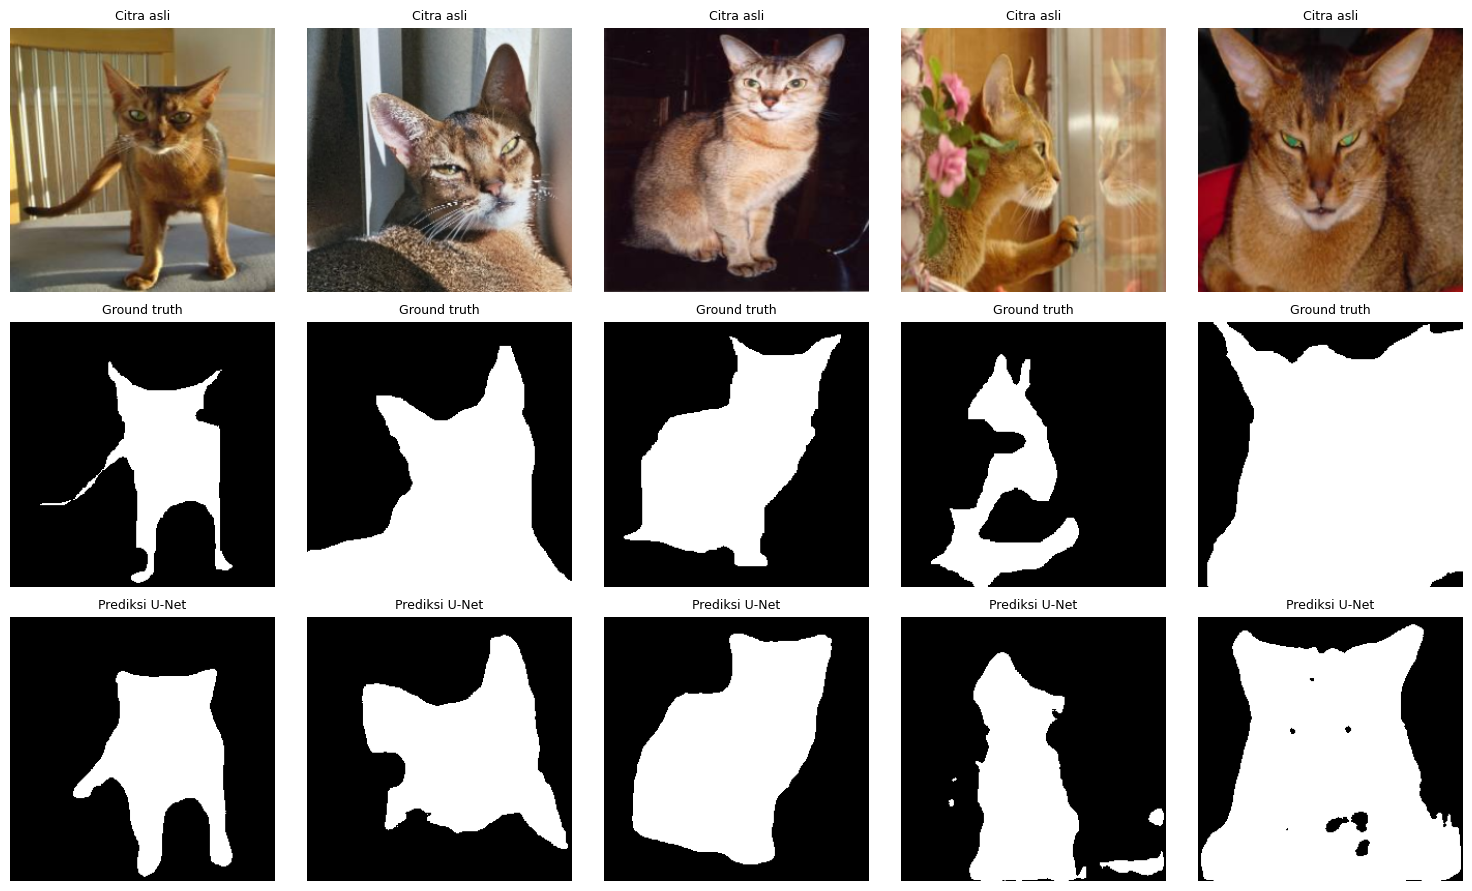

In [15]:

# === D3.2 Visualisasi prediksi U-Net ===

@torch.no_grad()
def prediksi(model, forward, idx):
    x = torch.stack(
        [ds_test[i][0] for i in idx]
    ).to(DEVICE)

    return (
        torch.sigmoid(forward(model, x)) > 0.5
    ).float().cpu()


# Mengambil lima gambar dari data uji
idx_vis = [0, 1, 2, 3, 4]

p_unet = prediksi(unet, fwd_unet, idx_vis)

fig, ax = plt.subplots(
    3, len(idx_vis),
    figsize=(3 * len(idx_vis), 9)
)

for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]

    # Baris pertama: gambar asli
    ax[0, j].imshow(denorm(x))
    ax[0, j].set_title("Citra asli", fontsize=9)

    # Baris kedua: masker asli
    ax[1, j].imshow(y[0], cmap="gray")
    ax[1, j].set_title("Ground truth", fontsize=9)

    # Baris ketiga: prediksi model
    ax[2, j].imshow(p_unet[j, 0], cmap="gray")
    ax[2, j].set_title("Prediksi U-Net", fontsize=9)

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/js05_d3_prediksi_unet.png",
    dpi=120
)

plt.show()



Hasil threshold 0.3:
Threshold: 0.3000
IoU hewan: 0.3439
IoU latar: 0.0000
mIoU: 0.1720
Dice: 0.5118
Pixel Accuracy: 0.3439

Hasil threshold 0.5:
Threshold: 0.5000
IoU hewan: 0.3439
IoU latar: 0.0000
mIoU: 0.1720
Dice: 0.5118
Pixel Accuracy: 0.3439

Hasil threshold 0.7:
Threshold: 0.7000
IoU hewan: 0.0000
IoU latar: 0.6561
mIoU: 0.3280
Dice: 0.0000
Pixel Accuracy: 0.6561

=== TABEL PERBANDINGAN THRESHOLD D3 ===
 Threshold  IoU hewan  IoU latar  mIoU   Dice  Pixel Accuracy
       0.3     0.3439     0.0000 0.172 0.5118          0.3439
       0.5     0.3439     0.0000 0.172 0.5118          0.3439
       0.7     0.0000     0.6561 0.328 0.0000          0.6561


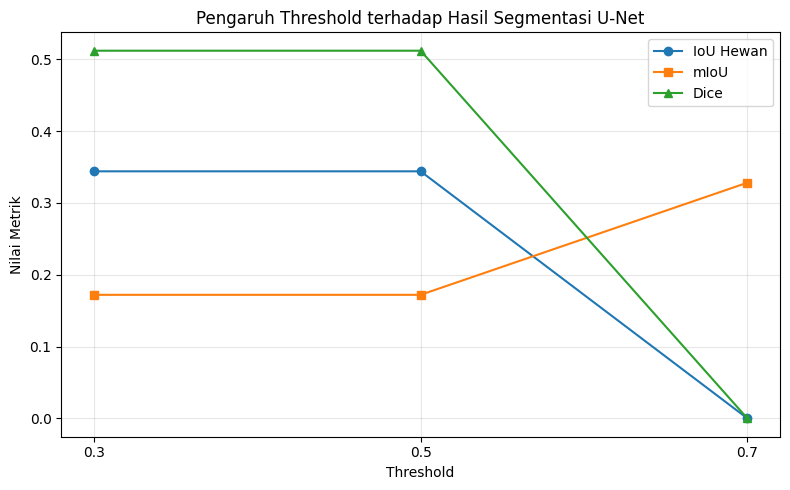


=== KESIMPULAN EKSPERIMEN D3 ===
Threshold dengan mIoU tertinggi: 0.7
mIoU tertinggi: 0.3280
IoU hewan: 0.0000
Dice: 0.0000

Gunakan tabel dan grafik di atas untuk membandingkan hasil threshold 0.3, 0.5, dan 0.7.


In [19]:

# ============================================================
# TUGAS KECIL D3: PERBANDINGAN THRESHOLD 0.3, 0.5, DAN 0.7
# ============================================================

import torch
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Fungsi evaluasi metrik segmentasi
# ------------------------------------------------------------

@torch.no_grad()
def evaluasi_threshold(model, forward, thr=0.5):
    model.eval()

    TP = 0.0
    FP = 0.0
    FN = 0.0
    TN = 0.0

    for x, y, valid in dl_test:
        x = x.to(DEVICE)
        y = y.to(DEVICE)
        valid = valid.to(DEVICE)

        # Probabilitas prediksi
        probabilitas = torch.sigmoid(forward(model, x))

        # Mengubah probabilitas menjadi masker biner
        pred = (probabilitas > thr).float()

        # Menghitung confusion matrix pada piksel valid
        TP += (pred * y * valid).sum().item()
        FP += (pred * (1 - y) * valid).sum().item()
        FN += ((1 - pred) * y * valid).sum().item()
        TN += ((1 - pred) * (1 - y) * valid).sum().item()

    # Menghitung metrik
    iou_hewan = TP / max(TP + FP + FN, 1)
    iou_latar = TN / max(TN + FN + FP, 1)

    miou = (iou_hewan + iou_latar) / 2
    dice = (2 * TP) / max(2 * TP + FP + FN, 1)
    pixel_acc = (TP + TN) / max(TP + TN + FP + FN, 1)

    return {
        "Threshold": thr,
        "IoU hewan": iou_hewan,
        "IoU latar": iou_latar,
        "mIoU": miou,
        "Dice": dice,
        "Pixel Accuracy": pixel_acc
    }


# ------------------------------------------------------------
# 2. Evaluasi dengan threshold 0.3, 0.5, dan 0.7
# ------------------------------------------------------------

thresholds = [0.3, 0.5, 0.7]
hasil_threshold = []

for thr in thresholds:
    hasil = evaluasi_threshold(unet, fwd_unet, thr=thr)
    hasil_threshold.append(hasil)

    print(f"\nHasil threshold {thr}:")
    for nama, nilai in hasil.items():
        print(
            f"{nama}: {nilai:.4f}"
            if isinstance(nilai, float)
            else f"{nama}: {nilai}"
        )


# ------------------------------------------------------------
# 3. Membuat tabel perbandingan
# ------------------------------------------------------------

tabel_d3 = pd.DataFrame(hasil_threshold)

print("\n=== TABEL PERBANDINGAN THRESHOLD D3 ===")
print(tabel_d3.round(4).to_string(index=False))


# ------------------------------------------------------------
# 4. Visualisasi pengaruh threshold terhadap IoU dan Dice
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    tabel_d3["Threshold"],
    tabel_d3["IoU hewan"],
    marker="o",
    label="IoU Hewan"
)

plt.plot(
    tabel_d3["Threshold"],
    tabel_d3["mIoU"],
    marker="s",
    label="mIoU"
)

plt.plot(
    tabel_d3["Threshold"],
    tabel_d3["Dice"],
    marker="^",
    label="Dice"
)

plt.xlabel("Threshold")
plt.ylabel("Nilai Metrik")
plt.title("Pengaruh Threshold terhadap Hasil Segmentasi U-Net")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    "figures/js05_d3_perbandingan_threshold.png",
    dpi=120
)
plt.show()


# ------------------------------------------------------------
# 5. Menampilkan threshold dengan mIoU tertinggi
# ------------------------------------------------------------

indeks_terbaik = tabel_d3["mIoU"].idxmax()
hasil_terbaik = tabel_d3.loc[indeks_terbaik]

print("\n=== KESIMPULAN EKSPERIMEN D3 ===")
print(
    f"Threshold dengan mIoU tertinggi: "
    f"{hasil_terbaik['Threshold']:.1f}"
)
print(f"mIoU tertinggi: {hasil_terbaik['mIoU']:.4f}")
print(f"IoU hewan: {hasil_terbaik['IoU hewan']:.4f}")
print(f"Dice: {hasil_terbaik['Dice']:.4f}")

print(
    "\nGunakan tabel dan grafik di atas untuk membandingkan "
    "hasil threshold 0.3, 0.5, dan 0.7."
)


In [22]:

# ============================================================
# PRAKTIKUM D4: TRANSFER LEARNING DENGAN DEEPLABV3
# Jobsheet 05 - Segmentasi Semantik Berbasis Deep Learning
# ============================================================

import torch
import torch.nn as nn
from torchvision.models.segmentation import (
    deeplabv3_mobilenet_v3_large,
    DeepLabV3_MobileNet_V3_Large_Weights
)

# D4.1 Memuat model DeepLabV3 pra-latih
set_seed(42)

dlv3 = deeplabv3_mobilenet_v3_large(
    weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
)

# Mengganti classifier dari 21 kelas menjadi 1 kanal
dlv3.classifier[4] = nn.Conv2d(
    256,
    1,
    kernel_size=1
)

# Menghapus auxiliary classifier
dlv3.aux_classifier = None

# Memindahkan model ke perangkat yang digunakan
dlv3 = dlv3.to(DEVICE)

# Menampilkan jumlah parameter model
jumlah_parameter = sum(
    p.numel() for p in dlv3.parameters()
) / 1e6

print(
    "Jumlah parameter DeepLabV3-MobileNetV3: "
    f"{jumlah_parameter:.2f} juta"
)

# D4.2 Menentukan fungsi forward
def fwd_dlv3(model, x):
    return model(x)["out"]

# D4.3 Mengatur learning rate backbone dan classifier
groups = [
    {
        "params": dlv3.backbone.parameters(),
        "lr": 1e-4
    },
    {
        "params": dlv3.classifier.parameters(),
        "lr": 1e-3
    }
]

# D4.4 Melatih model
hist_dlv3 = latih(
    dlv3,
    fwd_dlv3,
    CFG["EP_DLV3"],
    1e-3,
    "DeepLabV3-MobileNetV3 (pra-latih)",
    param_groups=groups
)

# D4.5 Mengevaluasi model
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(
    dlv3,
    fwd_dlv3
)

print("\nHasil evaluasi DeepLabV3:")
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))


Jumlah parameter DeepLabV3-MobileNetV3: 11.02 juta
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 1/6 loss latih 0.1819 loss uji 0.1292 (24 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 2/6 loss latih 0.0925 loss uji 0.1256 (49 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 3/6 loss latih 0.0718 loss uji 0.1033 (73 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 4/6 loss latih 0.0588 loss uji 0.1055 (97 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 5/6 loss latih 0.0526 loss uji 0.1115 (122 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 6/6 loss latih 0.0448 loss uji 0.1031 (146 s)

Hasil evaluasi DeepLabV3:
{'IoU_hewan': 0.9535, 'IoU_latar': 0.9752, 'mIoU': 0.9644, 'Dice': 0.9762, 'PixelAcc': 0.9836}


In [21]:

# === TUGAS KECIL D4: Freeze Backbone ===

import time

# Membekukan seluruh parameter backbone
for param in dlv3.backbone.parameters():
    param.requires_grad = False

# Hanya parameter classifier yang dilatih
for param in dlv3.classifier.parameters():
    param.requires_grad = True

# Optimizer hanya untuk classifier
groups_freeze = [
    {
        "params": dlv3.classifier.parameters(),
        "lr": 1e-3
    }
]

# Melatih model dengan backbone yang dibekukan
start_time = time.time()

hist_dlv3_freeze = latih(
    dlv3,
    fwd_dlv3,
    CFG["EP_DLV3"],
    1e-3,
    "DeepLabV3-MobileNetV3 (Freeze Backbone)",
    param_groups=groups_freeze
)

waktu_total_freeze = time.time() - start_time

# Evaluasi model
HASIL["DeepLabV3-MobileNetV3 (Freeze Backbone)"] = evaluasi(
    dlv3,
    fwd_dlv3
)

print("Hasil evaluasi:")
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (Freeze Backbone)"]))

print("Waktu total training: %.2f detik" % waktu_total_freeze)
print(
    "Rata-rata waktu per epoch: %.2f detik"
    % (waktu_total_freeze / CFG["EP_DLV3"])
)


[DeepLabV3-MobileNetV3 (Freeze Backbone)] epoch 1/6 loss latih 0.0458 loss uji 0.1054 (14 s)
[DeepLabV3-MobileNetV3 (Freeze Backbone)] epoch 2/6 loss latih 0.0431 loss uji 0.1093 (30 s)
[DeepLabV3-MobileNetV3 (Freeze Backbone)] epoch 3/6 loss latih 0.0384 loss uji 0.1080 (44 s)
[DeepLabV3-MobileNetV3 (Freeze Backbone)] epoch 4/6 loss latih 0.0380 loss uji 0.1163 (58 s)
[DeepLabV3-MobileNetV3 (Freeze Backbone)] epoch 5/6 loss latih 0.0359 loss uji 0.1149 (72 s)
[DeepLabV3-MobileNetV3 (Freeze Backbone)] epoch 6/6 loss latih 0.0344 loss uji 0.1196 (86 s)
Hasil evaluasi:
{'IoU_hewan': 0.9533, 'IoU_latar': 0.9751, 'mIoU': 0.9642, 'Dice': 0.9761, 'PixelAcc': 0.9835}
Waktu total training: 85.88 detik
Rata-rata waktu per epoch: 14.31 detik


In [23]:

# === D5.1 Muat SegFormer-B0 dan latih ===

import transformers
from transformers import SegformerForSemanticSegmentation

transformers.logging.set_verbosity_error()

set_seed(42)

segf = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b0",
    num_labels=1
).to(DEVICE)

print(
    "Jumlah parameter SegFormer-B0: %.2f juta"
    % (sum(p.numel() for p in segf.parameters()) / 1e6)
)


def fwd_segf(m, x):
    logit = m(pixel_values=x).logits

    return F.interpolate(
        logit,
        size=x.shape[-2:],
        mode="bilinear",
        align_corners=False
    )


hist_segf = latih(
    segf,
    fwd_segf,
    CFG["EP_SEGF"],
    3e-4,
    "SegFormer-B0 (pra-latih)"
)

HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(
    segf,
    fwd_segf
)

print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))


config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B0: 3.71 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pra-latih)] epoch 1/6 loss latih 0.3127 loss uji 0.1504 (42 s)
[SegFormer-B0 (pra-latih)] epoch 2/6 loss latih 0.1552 loss uji 0.1263 (71 s)
[SegFormer-B0 (pra-latih)] epoch 3/6 loss latih 0.1015 loss uji 0.1121 (99 s)
[SegFormer-B0 (pra-latih)] epoch 4/6 loss latih 0.0776 loss uji 0.1458 (134 s)
[SegFormer-B0 (pra-latih)] epoch 5/6 loss latih 0.0794 loss uji 0.1186 (167 s)
[SegFormer-B0 (pra-latih)] epoch 6/6 loss latih 0.0861 loss uji 0.1307 (196 s)
{'IoU_hewan': 0.9307, 'IoU_latar': 0.9624, 'mIoU': 0.9465, 'Dice': 0.9641, 'PixelAcc': 0.975}


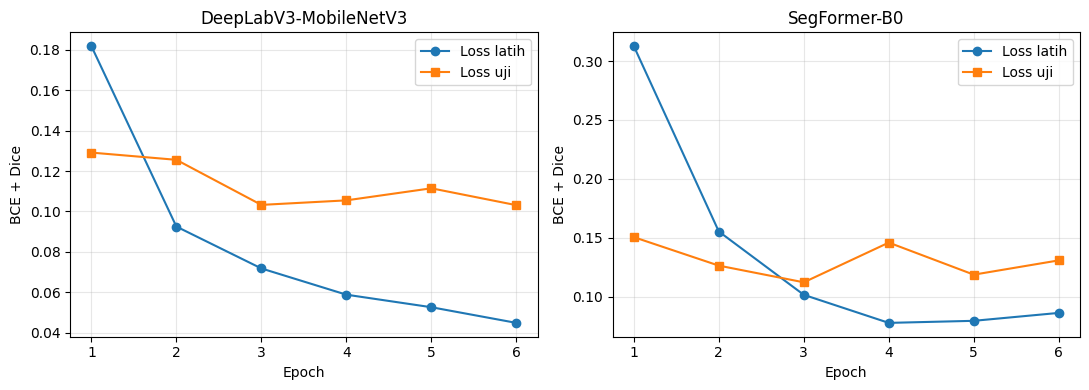

In [24]:

# === D5.2 Kurva loss model pra-latih ===

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, (nama, h) in zip(
    ax,
    [
        ("DeepLabV3-MobileNetV3", hist_dlv3),
        ("SegFormer-B0", hist_segf)
    ]
):
    ep = range(1, len(h["train"]) + 1)

    a.plot(ep, h["train"], "o-", label="Loss latih")
    a.plot(ep, h["test"], "s-", label="Loss uji")

    a.set_title(nama)
    a.set_xlabel("Epoch")
    a.set_ylabel("BCE + Dice")
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/js05_d5_kurva_pralatih.png",
    dpi=120
)
plt.show()


In [25]:

# === TUGAS KECIL D5: SegFormer-B1 ===

import time
import torch
import torch.nn.functional as F
import transformers
from transformers import SegformerForSemanticSegmentation

transformers.logging.set_verbosity_error()
set_seed(42)

# 1. Muat model SegFormer-B1
segf_b1 = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b1",
    num_labels=1
).to(DEVICE)

# 2. Hitung jumlah parameter
jumlah_parameter = sum(
    p.numel() for p in segf_b1.parameters()
)

print("Model: SegFormer-B1")
print("Jumlah parameter: %.2f juta" % (jumlah_parameter / 1e6))
print("Perangkat:", DEVICE)


# 3. Fungsi forward dengan upsampling
def fwd_segf_b1(model, x):
    logit = model(pixel_values=x).logits

    return F.interpolate(
        logit,
        size=x.shape[-2:],
        mode="bilinear",
        align_corners=False
    )


# 4. Latih model dan ukur waktu
if torch.cuda.is_available():
    torch.cuda.synchronize()

waktu_mulai = time.perf_counter()

hist_segf_b1 = latih(
    segf_b1,
    fwd_segf_b1,
    CFG["EP_SEGF"],
    3e-4,
    "SegFormer-B1 (pra-latih)"
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

waktu_total = time.perf_counter() - waktu_mulai
jumlah_epoch = len(hist_segf_b1["train"])
waktu_per_epoch = waktu_total / jumlah_epoch

print("\nHasil waktu pelatihan")
print("Total waktu: %.2f detik" % waktu_total)
print("Jumlah epoch:", jumlah_epoch)
print("Rata-rata waktu per epoch: %.2f detik" % waktu_per_epoch)


# 5. Evaluasi model
HASIL["SegFormer-B1 (pra-latih)"] = evaluasi(
    segf_b1,
    fwd_segf_b1
)

print("\nHasil evaluasi SegFormer-B1")
print(ringkas(HASIL["SegFormer-B1 (pra-latih)"]))


# 6. Simpan waktu pelatihan
WAKTU["SegFormer-B1 (pra-latih)"] = waktu_total


config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Model: SegFormer-B1
Jumlah parameter: 13.68 juta
Perangkat: cuda


model.safetensors: reconstructing file:   0%|          |  0.00B / 54.7MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B1 (pra-latih)] epoch 1/6 loss latih 0.2880 loss uji 0.1229 (49 s)
[SegFormer-B1 (pra-latih)] epoch 2/6 loss latih 0.1282 loss uji 0.1331 (96 s)
[SegFormer-B1 (pra-latih)] epoch 3/6 loss latih 0.0789 loss uji 0.1085 (145 s)
[SegFormer-B1 (pra-latih)] epoch 4/6 loss latih 0.0617 loss uji 0.0926 (193 s)
[SegFormer-B1 (pra-latih)] epoch 5/6 loss latih 0.0543 loss uji 0.0900 (241 s)
[SegFormer-B1 (pra-latih)] epoch 6/6 loss latih 0.0540 loss uji 0.1557 (289 s)

Hasil waktu pelatihan
Total waktu: 288.91 detik
Jumlah epoch: 6
Rata-rata waktu per epoch: 48.15 detik

Hasil evaluasi SegFormer-B1
{'IoU_hewan': 0.9283, 'IoU_latar': 0.9609, 'mIoU': 0.9446, 'Dice': 0.9628, 'PixelAcc': 0.974}


In [26]:

# === D6.1 TABEL PERBANDINGAN MODEL ===

import pandas as pd

model_fwd = [
    ("U-Net (dari nol)", unet, fwd_unet),
    ("DeepLabV3-MobileNetV3 (pra-latih)", dlv3, fwd_dlv3),
    ("SegFormer-B0 (pra-latih)", segf, fwd_segf),
]

# Tambahkan B1 jika sudah selesai dilatih
if "segf_b1" in globals() and "fwd_segf_b1" in globals():
    model_fwd.append(
        ("SegFormer-B1 (pra-latih)", segf_b1, fwd_segf_b1)
    )

baris = []

for nama, model, forward in model_fwd:
    hasil = HASIL.get(nama)

    # Evaluasi ulang jika hasil belum tersimpan
    if hasil is None:
        hasil = evaluasi(model, forward)
        HASIL[nama] = hasil

    jumlah_parameter = sum(
        p.numel() for p in model.parameters()
    ) / 1e6

    baris.append({
        "Model": nama,
        "Parameter (juta)": round(jumlah_parameter, 2),
        "IoU Hewan": round(hasil["IoU_hewan"], 4),
        "IoU Latar": round(hasil["IoU_latar"], 4),
        "mIoU": round(hasil["mIoU"], 4),
        "Dice": round(hasil["Dice"], 4),
        "Pixel Accuracy": round(hasil["PixelAcc"], 4),
        "Waktu latih (detik)": round(
            WAKTU.get(nama, float("nan")), 2
        )
    })

tabel_d6 = pd.DataFrame(baris)

print(tabel_d6.to_string(index=False))

tabel_d6.to_csv(
    f"{FIG_DIR}/js05_tabel_perbandingan_d6.csv",
    index=False
)


                            Model  Parameter (juta)  IoU Hewan  IoU Latar   mIoU   Dice  Pixel Accuracy  Waktu latih (detik)
                 U-Net (dari nol)              7.76     0.8268     0.9057 0.8662 0.9052          0.9350               877.66
DeepLabV3-MobileNetV3 (pra-latih)             11.02     0.9535     0.9752 0.9644 0.9762          0.9836               145.86
         SegFormer-B0 (pra-latih)              3.71     0.9307     0.9624 0.9465 0.9641          0.9750               195.75
         SegFormer-B1 (pra-latih)             13.68     0.9283     0.9609 0.9446 0.9628          0.9740               288.91


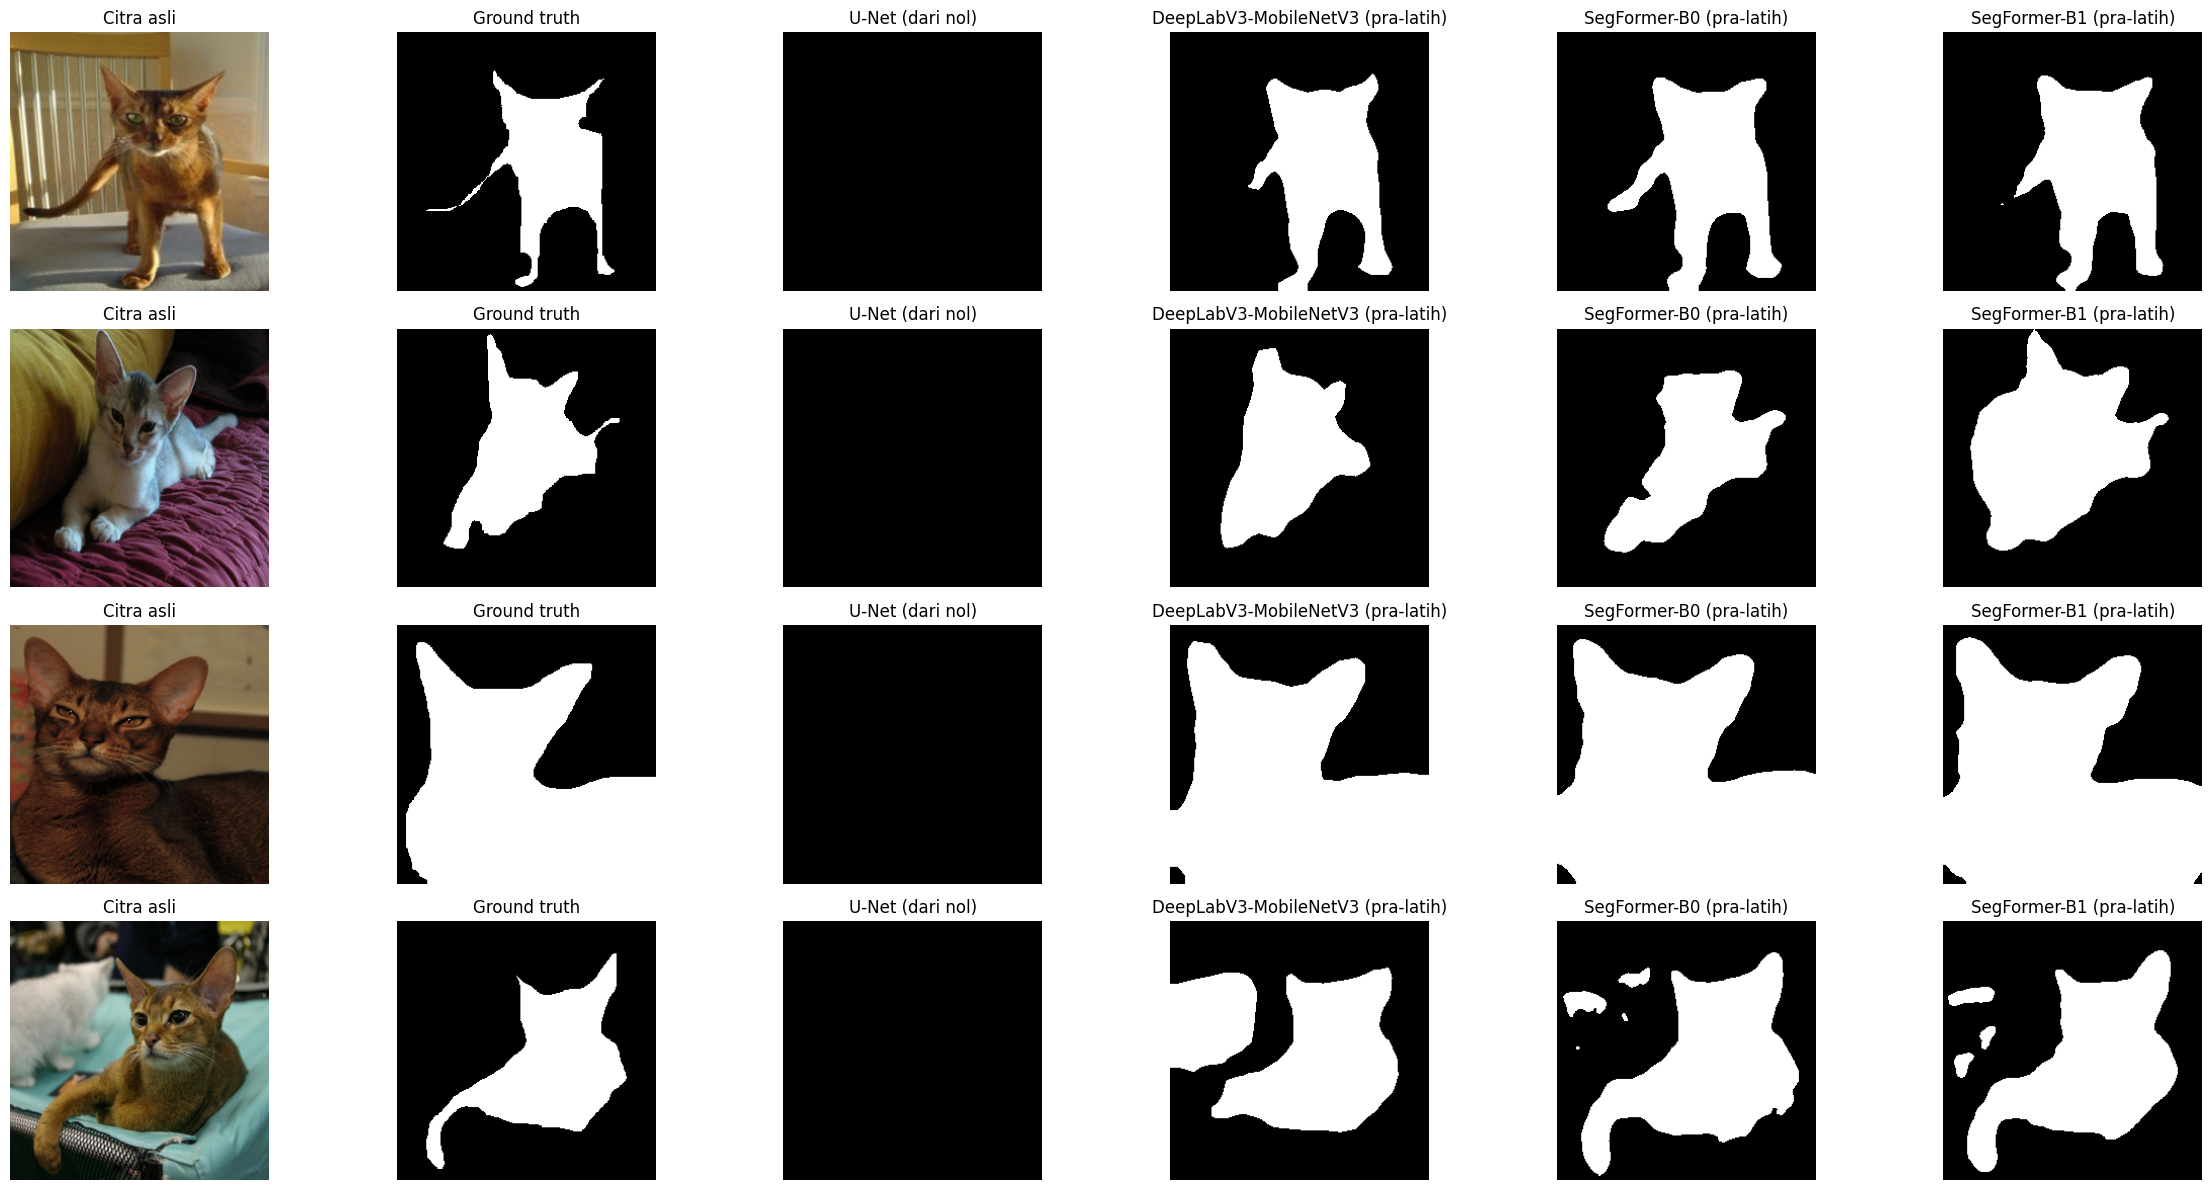

In [27]:

# === D6.2 VISUALISASI PREDIKSI ===

import matplotlib.pyplot as plt

idx_vis = [0, 5, 10, 15]
preds = {}

for nama, model, forward in model_fwd:
    preds[nama] = prediksi(
        model,
        forward,
        idx_vis
    )

fig, ax = plt.subplots(
    len(idx_vis),
    2 + len(model_fwd),
    figsize=(4 * (2 + len(model_fwd)), 3 * len(idx_vis))
)

for r, idx in enumerate(idx_vis):
    x, y, v = ds_test[idx]

    ax[r, 0].imshow(denorm(x))
    ax[r, 0].set_title("Citra asli")

    ax[r, 1].imshow(y[0], cmap="gray")
    ax[r, 1].set_title("Ground truth")

    for c, (nama, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(
            preds[nama][r, 0],
            cmap="gray"
        )
        ax[r, c + 2].set_title(nama)

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/js05_d6_perbandingan.png",
    dpi=110
)
plt.show()


Model dengan mIoU tertinggi: DeepLabV3-MobileNetV3 (pra-latih)
Indeks gambar dengan IoU terendah: [404, 95, 274, 147]
Nilai IoU: [0.0, 0.0037, 0.4261, 0.5053]


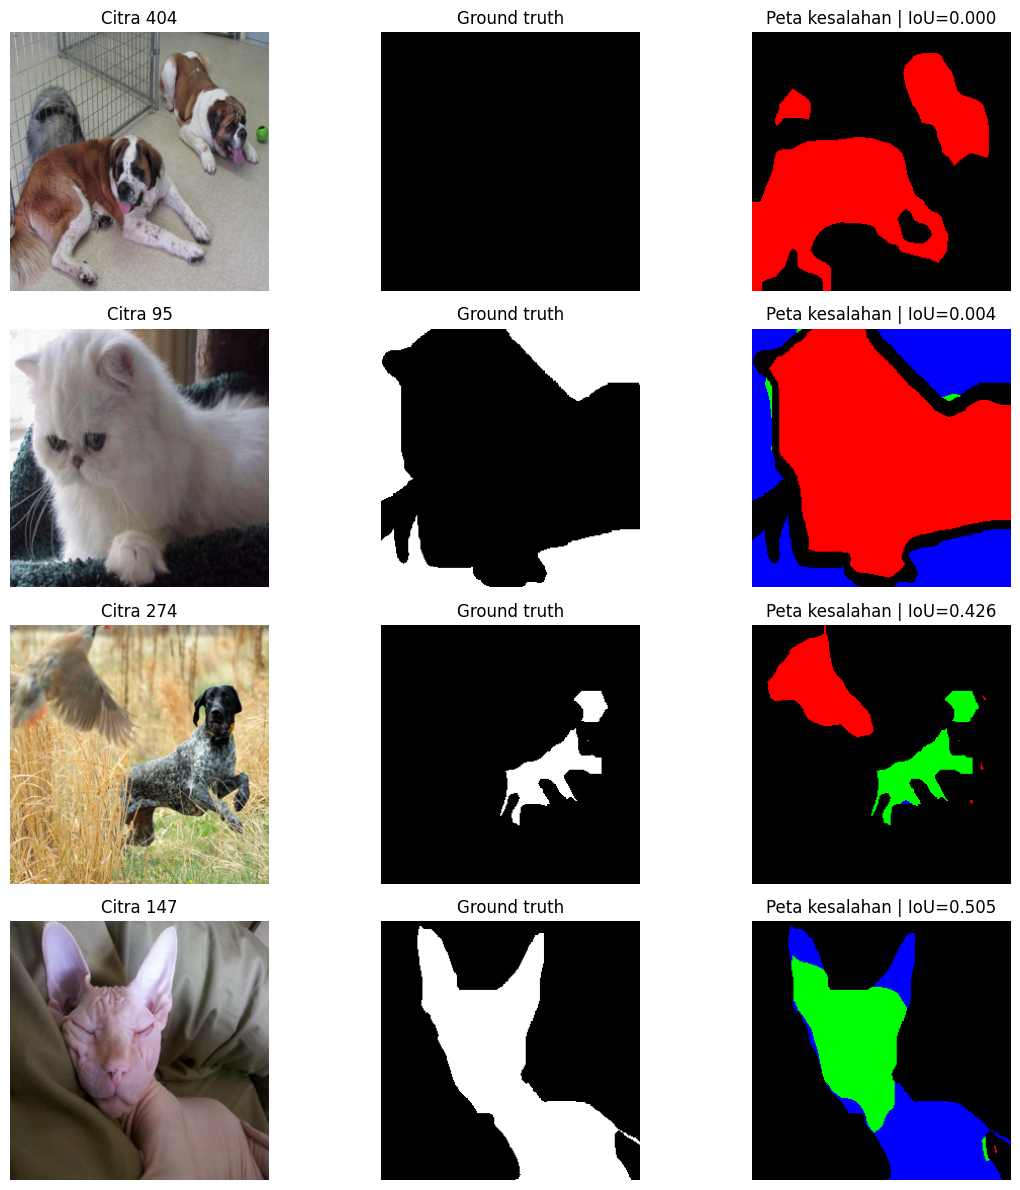

In [28]:

# === D6.3 ANALISIS KASUS TERBURUK ===

nama_terbaik = max(
    HASIL,
    key=lambda nama: HASIL[nama]["mIoU"]
)

model_terbaik = {
    nama: (model, forward)
    for nama, model, forward in model_fwd
}[nama_terbaik]

model, forward = model_terbaik

print("Model dengan mIoU tertinggi:", nama_terbaik)

hasil_iou = HASIL[nama_terbaik]["iou_per_citra"]

idx_buruk = sorted(
    range(len(hasil_iou)),
    key=lambda i: hasil_iou[i]
)[:4]

print("Indeks gambar dengan IoU terendah:", idx_buruk)
print("Nilai IoU:", [round(hasil_iou[i], 4) for i in idx_buruk])

pred_buruk = prediksi(
    model,
    forward,
    idx_buruk
)

fig, ax = plt.subplots(
    len(idx_buruk),
    3,
    figsize=(12, 3 * len(idx_buruk))
)

for r, idx in enumerate(idx_buruk):
    x, y, v = ds_test[idx]

    gt = y[0].cpu().numpy() > 0.5
    pr = pred_buruk[r, 0].numpy() > 0.5
    valid = v[0].cpu().numpy() > 0.5

    # TP = hijau, FP = merah, FN = biru
    peta = (
        gt.astype("uint8") * 0
    )
    peta = __import__("numpy").zeros(
        (*gt.shape, 3),
        dtype="uint8"
    )

    tp = pr & gt & valid
    fp = pr & ~gt & valid
    fn = ~pr & gt & valid

    peta[tp] = [0, 255, 0]
    peta[fp] = [255, 0, 0]
    peta[fn] = [0, 0, 255]

    ax[r, 0].imshow(denorm(x))
    ax[r, 0].set_title(f"Citra {idx}")

    ax[r, 1].imshow(gt, cmap="gray")
    ax[r, 1].set_title("Ground truth")

    ax[r, 2].imshow(peta)
    ax[r, 2].set_title(
        f"Peta kesalahan | IoU={hasil_iou[idx]:.3f}"
    )

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/js05_d6_kasus_terburuk.png",
    dpi=120
)
plt.show()


 Threshold  IoU Hewan  IoU Latar   mIoU   Dice
       0.3     0.9537     0.9752 0.9645 0.9763
       0.5     0.9535     0.9752 0.9644 0.9762
       0.7     0.9506     0.9739 0.9623 0.9747


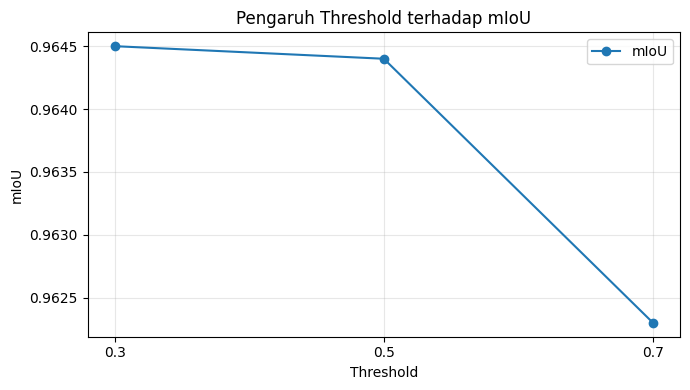


Threshold terbaik pada eksperimen:
Threshold    0.3000
IoU Hewan    0.9537
IoU Latar    0.9752
mIoU         0.9645
Dice         0.9763


In [30]:

# === TUGAS KECIL D6: PERBANDINGAN THRESHOLD ===

hasil_thr = {}

for thr in [0.3, 0.5, 0.7]:
    hasil_thr[thr] = evaluasi(
        model,
        forward,
        thr=thr
    )

tabel_thr = pd.DataFrame([
    {
        "Threshold": thr,
        "IoU Hewan": round(hasil["IoU_hewan"], 4),
        "IoU Latar": round(hasil["IoU_latar"], 4),
        "mIoU": round(hasil["mIoU"], 4),
        "Dice": round(hasil["Dice"], 4)
    }
    for thr, hasil in hasil_thr.items()
])

print(tabel_thr.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(
    tabel_thr["Threshold"],
    tabel_thr["mIoU"],
    "o-",
    label="mIoU"
)
plt.xlabel("Threshold")
plt.ylabel("mIoU")
plt.title("Pengaruh Threshold terhadap mIoU")
plt.xticks([0.3, 0.5, 0.7])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/js05_d6_eksperimen_threshold.png",
    dpi=120
)
plt.show()

terbaik_thr = tabel_thr.loc[tabel_thr["mIoU"].idxmax()]
print("\nThreshold terbaik pada eksperimen:")
print(terbaik_thr.to_string())
